# 06 · Revenue at risk, management segments & action plan
**Business question:** *How much revenue is at risk, where, and what should we do about it?*

* **Revenue at risk** = trailing-12m revenue × P(no order in next 12m). An *exposure* measure: it excludes shrinkage by customers who stay.
* **Value tier** = trailing-12m revenue (not CLV — CLV already discounts at-risk customers and would hide them).
* **At-risk trigger scales with value**: high-value accounts are flagged at ≥25% probability *or* when ≥30 days overdue against their own cadence; others at ≥50%.

In [1]:
import sys, pandas as pd
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
T = ROOT / 'reports' / 'tables'; F = ROOT / 'reports' / 'figures'
def fig(name): display(Image(filename=str(F / f'{name}.png')))

In [2]:
s = pd.read_csv(T / 'management_segments.csv'); s[['management_segment','customers','revenue_t12m','revenue_at_risk','flagged_accounts','clv_12m','avg_churn_prob','pct_revenue_t12m','pct_revenue_at_risk']]

,management_segment,customers,revenue_t12m,revenue_at_risk,flagged_accounts,clv_12m,avg_churn_prob,pct_revenue_t12m,pct_revenue_at_risk
0,1. Protect - Key Accounts,710,"5,240,557.380","174,849.873",0,"4,550,984.860",0.063,0.661,0.197
1,2. Rescue - High Value at Risk,107,"472,453.711","91,536.361",107,"373,971.079",0.232,0.060,0.103
2,3. Develop - Core Growth,1020,"1,194,878.191","217,267.607",0,"1,272,458.335",0.195,0.151,0.245
3,4. Win Back - Core at Risk,108,"112,918.240","53,555.933",108,"89,493.299",0.487,0.014,0.060
4,5. Nurture - New Customers,591,"379,899.440","112,702.904",260,"778,480.352",0.423,0.048,0.127
5,6. Automate - Low Value Active,834,"324,205.871","106,920.296",0,"527,098.124",0.344,0.041,0.120
6,7. Deprioritise - Low Value Lapsing,880,"208,638.460","130,488.668",880,"304,653.292",0.640,0.026,0.147
7,8. Lapsed (>12m) - Win-back Pool,1589,0.000,0.000,0,"293,625.110",NaN,0.000,0.000


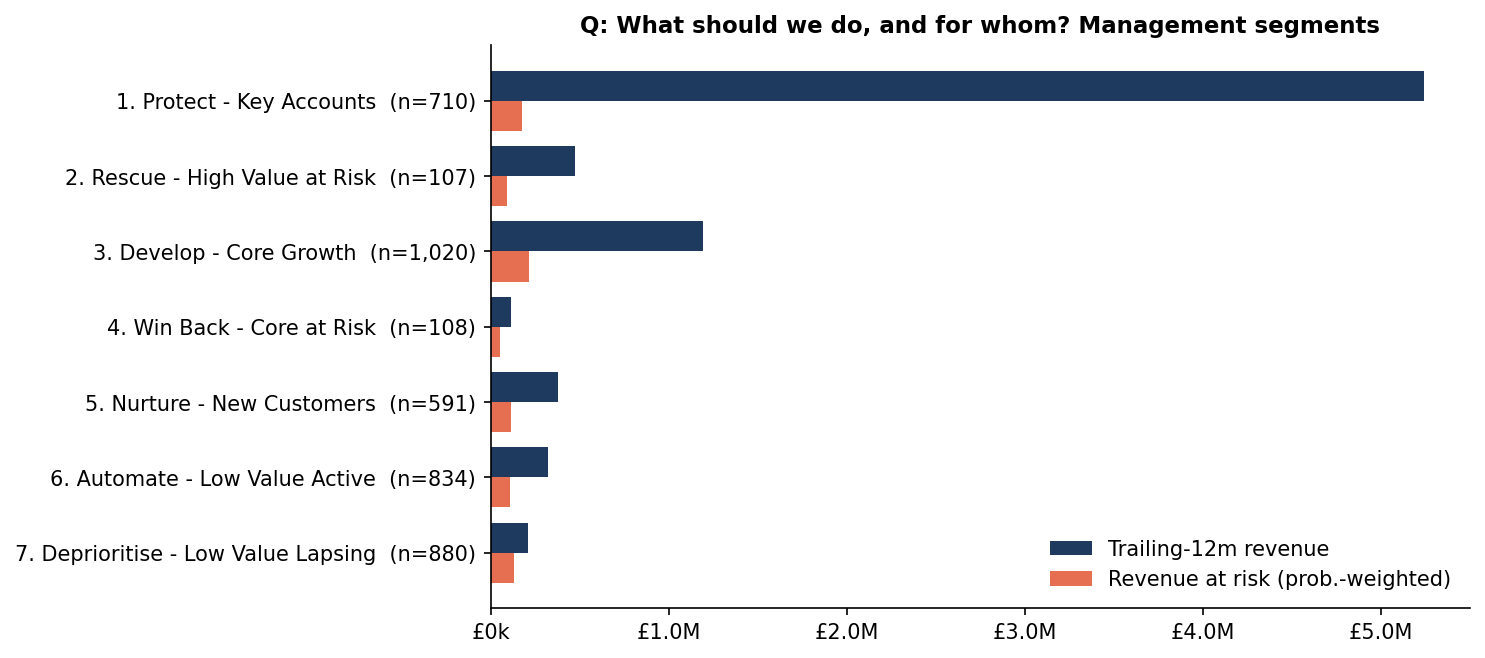

In [3]:
fig('11_management_segments')

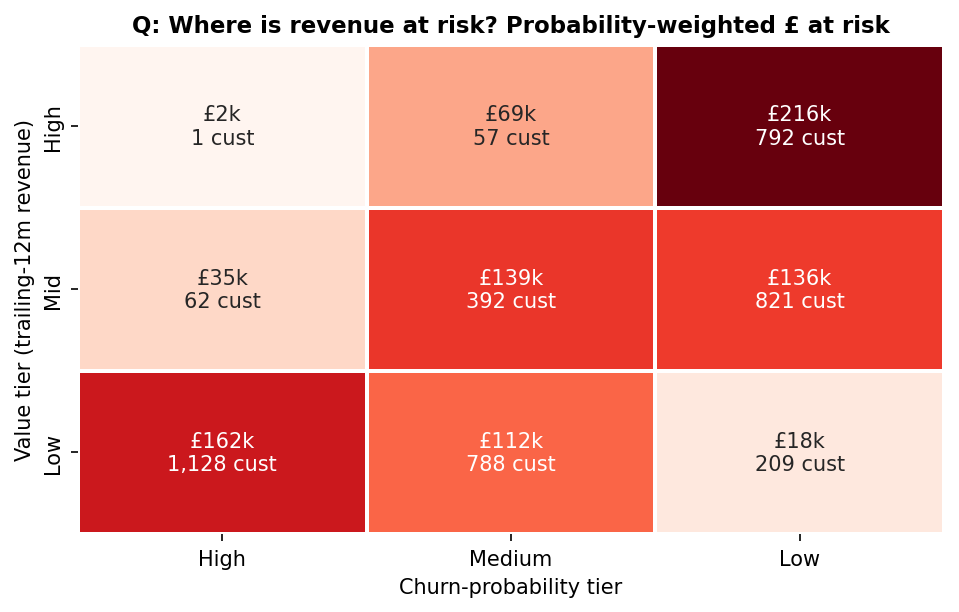

In [4]:
fig('10_value_risk_grid')

In [5]:
pd.read_csv(T / 'revenue_at_risk_concentration.csv')

,share_of_revenue_at_risk,accounts_needed
0,0.250,296
1,0.500,978
2,0.800,2362


**Read-out (calculated)**
* **£887k** of **£7.94M** trailing-12m revenue (11.2%) is at risk. Cross-check: churned customers took £1.02M of prior-year revenue last year — same order of magnitude.
* Risk is **diffuse**: 978 accounts hold half of it. Account managers alone cannot address it; most needs automated, cadence-triggered programmes.
* **Rescue segment:** 107 high-value accounts, £472k of trailing revenue, flagged now.

In [6]:
pd.read_csv(T / 'high_value_high_risk_top100.csv').head(15)

,priority_rank,customer_id,country,management_segment,value_tier,risk_tier,revenue_t12m,churn_prob_12m,revenue_at_risk,clv_12m,recency_days,frequency,avg_gap_days,cadence_status,at_risk_reason,rfm_segment,historic_revenue
0,1,16029,United Kingdom,2. Rescue - High Value at Risk,High,Low,"56,098.410",0.049,"2,726.337","37,853.404",39,103.000,6.800,Lapsed,Overdue vs own buying cadence,Loyal Customers,"97,066.710"
1,2,15749,United Kingdom,2. Rescue - High Value at Risk,High,Medium,"21,535.900",0.265,"5,710.725","11,744.105",236,2.000,97.000,Insufficient history,Elevated churn probability,Hibernating,"21,535.900"
2,3,15513,United Kingdom,2. Rescue - High Value at Risk,High,Low,"13,206.580",0.046,604.711,"10,895.950",32,35.000,19.500,Slipping,Overdue vs own buying cadence,Loyal Customers,"25,959.160"
3,4,12939,United Kingdom,2. Rescue - High Value at Risk,High,Low,"11,581.800",0.090,"1,048.145","10,576.773",65,20.000,33.300,Slipping,Overdue vs own buying cadence,Loyal Customers,"25,264.800"
4,5,16180,United Kingdom,2. Rescue - High Value at Risk,High,Low,"10,217.480",0.196,"2,005.663","7,374.782",101,13.000,36.200,Slipping,Overdue vs own buying cadence,Loyal Customers,"16,170.270"
5,6,17865,United Kingdom,2. Rescue - High Value at Risk,High,Low,"10,200.590",0.042,433.270,"10,637.390",31,45.000,16.100,Slipping,Overdue vs own buying cadence,Loyal Customers,"25,584.750"
6,7,16843,United Kingdom,2. Rescue - High Value at Risk,High,Low,"10,183.820",0.061,623.115,"7,924.910",43,34.000,20.800,Slipping,Overdue vs own buying cadence,Loyal Customers,"19,528.780"
7,8,12590,Germany,2. Rescue - High Value at Risk,High,Medium,"9,338.380",0.362,"3,383.365",315.927,191,1.000,NaN,Insufficient history,Elevated churn probability,Hibernating,"9,330.480"
8,9,14952,United Kingdom,2. Rescue - High Value at Risk,High,Low,"8,015.790",0.076,608.586,"7,119.629",47,32.000,21.800,Slipping,Overdue vs own buying cadence,Loyal Customers,"17,347.250"
9,10,16745,United Kingdom,2. Rescue - High Value at Risk,High,Low,"7,157.100",0.181,"1,296.486","4,221.989",87,17.000,14.100,Lapsed,Overdue vs own buying cadence,Loyal Customers,"7,157.100"


In [7]:
pd.read_csv(T / 'action_playbook.csv')

,management_segment,objective,action,channel,success_kpi,spend_guidance
0,1. Protect - Key Accounts,Retain and deepen share of wallet,Named account owner; quarterly business review...,Account manager (phone / visit),Net revenue retention of segment >= 100%,Highest cost-to-serve justified; cap at a set ...
1,2. Rescue - High Value at Risk,Stop the loss before it happens (highest £ pri...,Personal outreach within 2 weeks ranked by rev...,"Account manager call, then tailored email",Share of segment placing an order within 90 da...,Incentive per account <= margin x revenue at r...
2,3. Develop - Core Growth,Grow order frequency / basket,Replenishment reminders timed to each customer...,Automated email + sales team for top of tier,Orders per customer; AOV; migration to High value,Low-cost automation first; human time for top ...
3,4. Win Back - Core at Risk,Re-activate before they lapse,Triggered win-back when overdue ratio > 1.5x t...,Automated email sequence,Reactivation rate within 60 days,Offer value capped by expected margin of one a...
4,5. Nurture - New Customers,Convert first order into second order,Onboarding series; second-order incentive insi...,Automated email,2nd-order rate within 90 days of first,Moderate — a 2nd order is the strongest predic...
5,6. Automate - Low Value Active,Serve profitably at low cost,"Self-service, standard newsletters, minimum-or...",Newsletter / website,Cost-to-serve per £ revenue,Minimal; no discretionary incentives
6,7. Deprioritise - Low Value Lapsing,Let go gracefully; learn why,One low-cost reactivation email; include in lo...,Email,Survey response insights,Near zero
7,8. Lapsed (>12m) - Win-back Pool,Opportunistic reactivation,Seasonal campaign before the Sep–Nov peak; hig...,Seasonal email; calls for top historical spenders,Reactivated customers and £ revenue,Only for accounts with high historical value


In [8]:
pd.read_csv(T / 'retention_scenarios.csv')

,save_rate,recovered_revenue_all_at_risk,recovered_revenue_rescue_segment_only
0,0.100,"88,732.164","9,153.636"
1,0.200,"177,464.329","18,307.272"
2,0.300,"266,196.493","27,460.908"


Scenario values use **assumed** save rates. The Excel model (`excel/retention_investment_model.xlsx`) lets Finance set margin, save rates and contact costs; under illustrative assumptions the Rescue outreach breaks even at an ~12% save rate, while calling every low-risk key account does not pay back.

## What should management do differently?
1. **This month:** account managers call the 107 Rescue accounts, largest first (list provided), and record the reason for any slowdown.
2. **Next quarter:** launch cadence-triggered win-back emails for Mid-value at-risk and a second-order programme for new customers.
3. **Measure causally:** hold out a random 10–20% of each targeted segment so the true save rate is measured, not assumed.
4. **Stop spending discretionary incentives** on the Low-value Lapsing segment.